# Lane Detector From Scratch

We design and build the vision lane detector for the F1 racer, one block per notebook.

**Specification**

- Input: one RGB camera frame, 128 × 128, `uint8`.
- Output: `e_lat` — lateral offset of the track centre (±1 = car on a boundary); `e_heading` — track direction relative to the car (rad); `confidence` — 0..1.
- Constraint: cheap enough for every control step, no learned model.

**Architecture**

```
frame ─► mask ─► scan ─► centre ─► camera ─► errors
         02      03      05        04        06
       colour   blobs   which     px → m    e_lat, e_heading,
       → 0..1   per row are lines           confidence
```

| Notebook | Block | Question |
|---|---|---|
| 01 the frame | — | What does the camera give us? |
| 02 mask | `lanedet/mask.py` | Which pixels are paint? |
| 03 scan | `lanedet/scan.py` | Where do the lines cross a row? |
| 04 camera | `lanedet/camera.py` | How do pixels map to metres? |
| 05 centre | `lanedet/centre.py` | Which blobs are boundaries, where is the centre? |
| 06 detector | `lanedet/detector.py` | How do the blocks connect into control errors? |
| 07 video | `lanedet/overlay.py` | Does it hold up frame after frame? |
| 08 tune | — | What breaks it, which parameters fix it? |

**Working method**

- Each block is a small module in `lanedet/`, saved by a `%%writefile` cell. Later notebooks import it.
- `SyntheticTrack` renders a flat track through a known pinhole camera, so every frame comes with the exact answer.
- Each notebook ends with a check cell. It runs silently when the block is correct.
- Run the notebooks in order, each top to bottom.

In [1]:
%load_ext autoreload
%autoreload 2
import math
import numpy as np
import matplotlib.pyplot as plt
from helpers import SyntheticTrack, synthetic_drive, show, table, use_style
use_style()

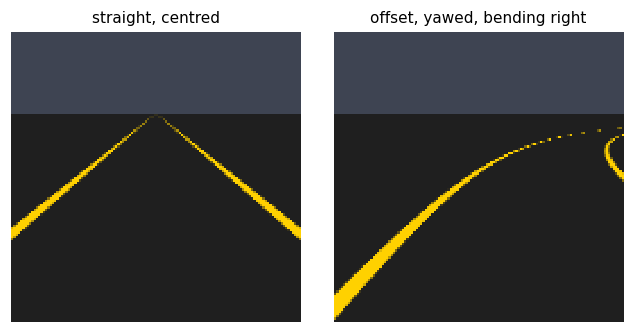

In [2]:
show(
    [SyntheticTrack().render(), SyntheticTrack(offset=0.08, yaw=0.1, curvature=0.8).render()],
    ["straight, centred", "offset, yawed, bending right"],
)